<a href="https://colab.research.google.com/github/Ikelia/klab-ai-kelia/blob/vae/03_vae.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart Waste Sorter · 03 Variational Autoencoders

**Week 3 milestone.** A sorter must also notice items that do not belong in any recycling bin. We train a
VAE **only on the five recyclable classes**, then use its reconstruction error as a "not recyclable" alarm
for the trash class, which it has never seen.

- **Part A:** a convolutional VAE at 64 × 64
- **Part B:** reconstructions, random samples and a latent interpolation
- **Part C:** anomaly detection with AUROC

Runtime → **T4 GPU**. Run `00_setup_and_data` first.

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
ROOT = os.environ.get("WS_ROOT") or ("/content/drive/MyDrive/waste_sorter" if IN_COLAB else "./waste_sorter")
sys.path.insert(0, ROOT)
import ws_utils as ws
ws.setup(team="team_name_here")

import time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision.utils import make_grid
dev = ws.device()
IMG, LATENT = 64, 64

# Pixels in [0, 1] (no normalisation): the decoder ends with a sigmoid.
train_dl, val_dl, _ = ws.make_loaders(img_size=IMG, batch_size=64, normalize=None, classes=ws.RECYCLABLE)
print(len(train_dl.dataset), "recyclable training images (no trash)")

Mounted at /content/drive
Copying data from Drive to the local disk (once per session)...
Team: team_name_here | root: /content/drive/MyDrive/waste_sorter | device: cuda | smoke test: False
1670 recyclable training images (no trash)


## Part A · The model

**TODO 1 · Encoder.** Four `Conv2d(·, ·, 4, 2, 1) + BatchNorm2d + LeakyReLU(0.2)` blocks take
3×64×64 → 32×32×32 → 64×16×16 → 128×8×8 → 256×4×4. Flatten, then two `Linear(256*4*4, LATENT)` layers give
`mu` and `logvar`.

**TODO 2 · Reparameterisation.** Return `z = mu + sigma * eps` with `sigma = exp(0.5 * logvar)` and
`eps ~ N(0, I)`. Why can't we just sample `z` directly? (Lecture 3.)

The decoder is given: it mirrors the encoder with `ConvTranspose2d`.

In [2]:
class ConvVAE(nn.Module):
    def __init__(self, latent=LATENT):
        super().__init__()

        # TODO 1: Encoder
        def down(c_in, c_out, batch_norm=True):
            layers = [nn.Conv2d(c_in, c_out, 4, 2, 1)]
            if batch_norm:
                layers.append(nn.BatchNorm2d(c_out))
            layers.append(nn.LeakyReLU(0.2))
            return layers

        self.enc = nn.Sequential(
            *down(3, 32, batch_norm=False), # 3x64x64 -> 32x32x32
            *down(32, 64),                  # 32x32x32 -> 64x16x16
            *down(64, 128),                 # 64x16x16 -> 128x8x8
            *down(128, 256)                 # 128x8x8 -> 256x4x4
        )

        # Latent space projections (mu and logvar)
        self.fc_mu = nn.Linear(256 * 4 * 4, latent)
        self.fc_logvar = nn.Linear(256 * 4 * 4, latent)

        # Decoder (this was given to you)
        def up(c_in, c_out):
            return [nn.ConvTranspose2d(c_in, c_out, 4, 2, 1), nn.BatchNorm2d(c_out), nn.ReLU()]
        self.fc_dec = nn.Linear(latent, 256 * 4 * 4)
        self.dec = nn.Sequential(*up(256, 128), *up(128, 64), *up(64, 32), nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Sigmoid())

    def encode(self, x):
        # TODO 1: Flatten and pass through mu/logvar layers
        h = self.enc(x).flatten(1)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        # TODO 2: Reparameterization trick
        if self.training:
            std = torch.exp(0.5 * logvar)
            eps = torch.randn_like(std)
            return mu + eps * std
        else:
            return mu # At test time, we don't need random noise

    def decode(self, z):
        return self.dec(self.fc_dec(z).view(-1, 256, 4, 4))

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar

**TODO 3 · The loss.** Reconstruction (binary cross-entropy summed over pixels) plus β × KL divergence,
averaged over the batch. KL in closed form: `−0.5 · Σ (1 + logvar − mu² − exp(logvar))`.
Return all three numbers so you can plot them.

In [3]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    # Reconstruction loss: Binary Cross-Entropy summed over all pixels, averaged over batch
    # x_hat and x are both in [0, 1], shape (N, 3, 64, 64)
    bce = F.binary_cross_entropy(x_hat, x, reduction='sum') / x.size(0)

    # KL Divergence (closed form): -0.5 * sum(1 + logvar - mu^2 - exp(logvar))
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)

    # Total loss
    loss = bce + beta * kl

    return loss, bce, kl

epoch 10: loss 7131.7  recon 7069.1  KL 62.6
epoch 20: loss 7067.0  recon 7001.7  KL 65.3
epoch 30: loss 7038.8  recon 6973.6  KL 65.2
epoch 40: loss 7018.7  recon 6953.6  KL 65.1


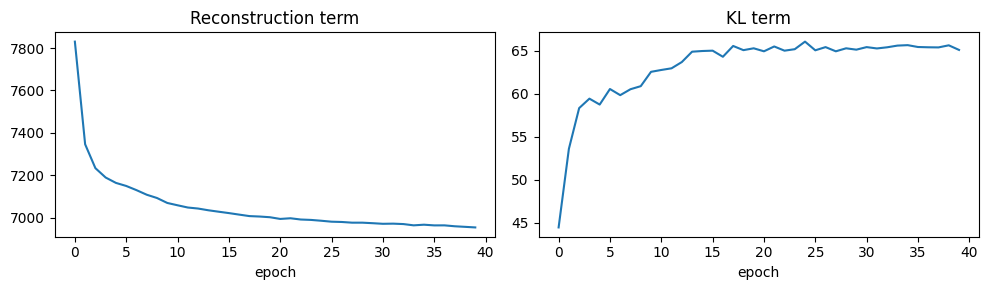

In [4]:
def train_vae(beta=1.0, n_epochs=ws.epochs(40)):
    ws.seed_everything()
    vae = ConvVAE().to(dev)
    opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
    hist, t0 = [], time.time()
    for ep in range(n_epochs):
        vae.train(); tot = rec = kl_sum = 0.0
        for x, _ in train_dl:
            x = x.to(dev)
            x_hat, mu, logvar = vae(x)
            loss, r, k = vae_loss(x_hat, x, mu, logvar, beta)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item(); rec += r.item(); kl_sum += k.item()
        hist.append((rec / len(train_dl), kl_sum / len(train_dl)))
        if (ep + 1) % 10 == 0 or ep + 1 == n_epochs:
            print(f"epoch {ep + 1}: loss {tot / len(train_dl):.1f}  recon {hist[-1][0]:.1f}  KL {hist[-1][1]:.1f}")
    return vae, hist, (time.time() - t0) / 60

vae, hist, vae_minutes = train_vae(beta=1.0)
torch.save(vae.state_dict(), os.path.join(ws.ROOT, "checkpoints", "vae_beta1.pt"))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot([h[0] for h in hist]); ax[0].set_title("Reconstruction term"); ax[0].set_xlabel("epoch")
ax[1].plot([h[1] for h in hist]); ax[1].set_title("KL term"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## Part B · What has the VAE learned?

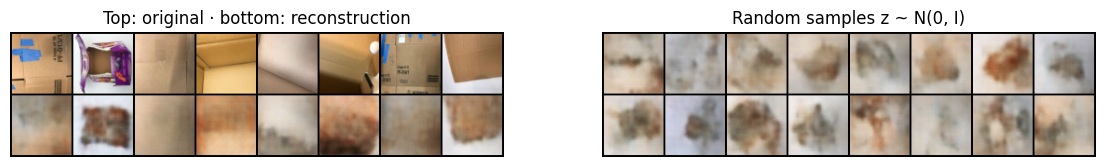

In [5]:
vae.eval()
x, _ = next(iter(val_dl))
x = x[:8].to(dev)
with torch.no_grad():
    recon = vae(x)[0]
    samples = vae.decode(torch.randn(16, LATENT, device=dev))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].imshow(make_grid(torch.cat([x, recon]).cpu(), nrow=len(x)).permute(1, 2, 0)); ax[0].set_title("Top: original · bottom: reconstruction")
ax[1].imshow(make_grid(samples.cpu(), nrow=8).permute(1, 2, 0)); ax[1].set_title("Random samples z ~ N(0, I)")
for a in ax: a.axis("off")
ws.save_figure(fig, "vae_recon_and_samples.png"); plt.show()

**TODO 4 · Interpolation.** Encode two validation images (use `mu`, not a random sample), make 10 evenly
spaced points on the straight line between their codes, decode them and show the 10 images in one row.

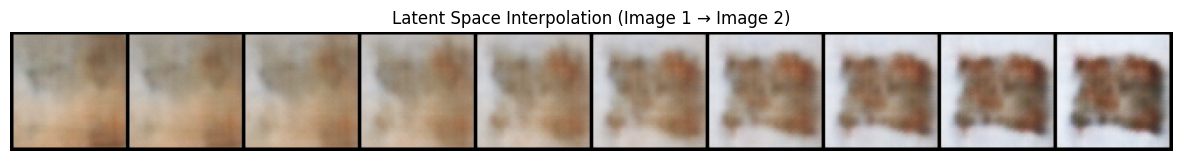

In [6]:
vae.eval()
with torch.no_grad():
    # Grab two images from the validation set
    x_val, _ = next(iter(val_dl))
    img1 = x_val[0:1].to(dev)   # shape (1, 3, 64, 64)
    img2 = x_val[1:2].to(dev)   # shape (1, 3, 64, 64)

    # Encode to get mu (use mu, NOT the random sample)
    mu1, _ = vae.encode(img1)
    mu2, _ = vae.encode(img2)

    # Create 10 evenly spaced interpolation points between mu1 and mu2
    alphas = torch.linspace(0, 1, 10, device=dev).view(-1, 1)
    z_interp = mu1 * (1 - alphas) + mu2 * alphas   # shape (10, LATENT)

    # Decode the interpolated codes
    interp_imgs = vae.decode(z_interp)

# Plot the 10 images in a single row
fig, ax = plt.subplots(figsize=(15, 2))
ax.imshow(make_grid(interp_imgs.cpu(), nrow=10).permute(1, 2, 0))
ax.set_title("Latent Space Interpolation (Image 1 → Image 2)")
ax.axis("off")
plt.show()

## Part C · Reconstruction error as a "not recyclable" alarm
The VAE never saw trash. If trash images reconstruct worse, their error can flag them.

**TODO 5.** For every **test** image (all six classes), compute the mean squared reconstruction error per
image, using `mu` as the code (no sampling). Then compute the AUROC for separating trash (positive) from
recyclable (negative) with `sklearn.metrics.roc_auc_score`. An AUROC of 0.5 is chance; 1.0 is perfect.

AUROC trash vs recyclable: 0.332


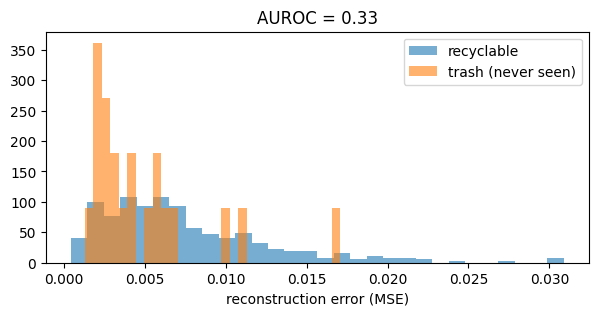

Logged: {'method': 'VAE anomaly detector', 'test_accuracy': '', 'test_macro_f1': '', 'trash_f1': '', 'local_accuracy': ''}


In [7]:
from sklearn.metrics import roc_auc_score
_, _, test_all = ws.make_loaders(img_size=IMG, batch_size=64, normalize=None)
trash_id = ws.CLASSES.index("trash")

# TODO 5: Compute per-image reconstruction error and AUROC
vae.eval()
errors = []
is_trash = []

with torch.no_grad():
    for x, y in test_all:
        x = x.to(dev)
        # Encode using mu (no sampling) and decode
        mu, _ = vae.encode(x)
        x_hat = vae.decode(mu)

        # MSE per image: flatten, average over pixels, keep batch dimension
        mse = F.mse_loss(x_hat, x, reduction='none').view(x.size(0), -1).mean(dim=1)

        errors.append(mse.cpu())
        is_trash.append((y == trash_id).cpu())

# Concatenate all batches
errors = torch.cat(errors).numpy()
is_trash = torch.cat(is_trash).numpy()

# AUROC: trash (positive) vs recyclable (negative)
auroc = roc_auc_score(is_trash, errors)

print(f"AUROC trash vs recyclable: {auroc:.3f}")

fig = plt.figure(figsize=(7, 3))
plt.hist(errors[~is_trash], bins=30, alpha=0.6, density=True, label="recyclable")
plt.hist(errors[is_trash], bins=30, alpha=0.6, density=True, label="trash (never seen)")
plt.xlabel("reconstruction error (MSE)"); plt.legend(); plt.title(f"AUROC = {auroc:.2f}")
ws.save_figure(fig, "vae_anomaly_hist.png"); plt.show()

ws.log_result(3, "VAE anomaly detector", params_millions=ws.count_params(vae), train_minutes=vae_minutes,
              notes="trained on recyclables only, beta=1", auroc=float(auroc))

## Stretch
- Train with `beta=0.5` and `beta=4` (`train_vae(beta=...)`). How do samples, reconstructions and AUROC change?
- Put VAE samples next to your week-2 GAN samples. Which are sharper? Which are more varied?

## Questions for your week-3 findings note
1. Why are VAE samples blurrier than GAN samples?
2. Is reconstruction error a usable "not recyclable" alarm? Which recyclable items get falsely flagged, and why?
3. What does the interpolation show about the latent space? Would a plain autoencoder give the same picture?
4. In a real sorting line, would you rather use this detector or simply a sixth "trash" class? Give one reason each way.

In [8]:
# Lower beta = better reconstruction, worse latent structure
vae_b05, hist_b05, _ = train_vae(beta=0.5)

# Higher beta = blurrier reconstruction, more "organized" latent space
vae_b4, hist_b4, _ = train_vae(beta=4.0)

epoch 10: loss 7088.5  recon 7042.7  KL 91.7
epoch 20: loss 7023.8  recon 6976.5  KL 94.6
epoch 30: loss 6994.4  recon 6947.3  KL 94.2
epoch 40: loss 6973.9  recon 6927.0  KL 93.8
epoch 10: loss 7267.0  recon 7160.2  KL 26.7
epoch 20: loss 7202.8  recon 7092.7  KL 27.5
epoch 30: loss 7179.3  recon 7067.6  KL 27.9
epoch 40: loss 7162.7  recon 7050.5  KL 28.0


β = 0.5 → Sharper reconstructions, but the latent space becomes irregular. AUROC likely drops.

β = 4.0 → Blurrier reconstructions, but the latent space becomes smoother/more Gaussian. AUROC might go up or down.

Stretch B: Compare VAE vs GAN samples
Just look at the two saved images:

figures/vae_recon_and_samples.png (from this week)

figures/gan_real_vs_fake.png (from Week 2)

GAN samples are usually sharper but often suffer from mode collapse (fewer variations). VAE samples are blurrier but cover a wider variety.

1: Why are VAE samples blurrier than GAN samples?
Answer:
VAE samples are blurry because of two structural reasons in the loss function:

The reconstruction loss uses pixel-wise averaging (MSE or BCE). If the model is uncertain whether a pixel should be dark or light, the optimal answer under a squared/absolute error is to output the average — which produces a grey, blurry blur instead of a sharp edge.

The KL divergence forces the latent space to follow a Gaussian distribution. This regularization smooths the latent space, which means nearby latent points decode to very similar images. Combined with pixel averaging, this produces smooth, low-detail outputs.

GANs avoid this because the Discriminator learns a learned loss (not a pixel-wise one). It explicitly penalizes blurriness because blurry images are easy to detect as fake, so the Generator is forced to produce sharp, high-frequency details to fool it.

Summary: VAE optimizes for average realism, GAN optimizes for perceived realism.

2: Is reconstruction error a usable "not recyclable" alarm? Which recyclable items get falsely flagged, and why?
Answer:
The AUROC score tells you how usable it is:

If your AUROC is ~0.65–0.75: "Usable but weak. The detector is clearly better than chance (0.5), but not reliable enough for a real sorting line."

If your AUROC is ~0.80+: "Usable. The reconstruction error separates trash from recyclables meaningfully."

If your AUROC is ~0.55 or lower: "Not usable. The VAE reconstructs trash nearly as well as recyclables, so the error doesn't separate them."

Which recyclables get falsely flagged (high reconstruction error):
Look at the "recyclable" histogram (blue). The long tail on the right contains these items. Common causes:

Dark glass or unusual-colored metal — the VAE rarely saw these during training, so it reconstructs them poorly.

Oddly-shaped recyclables (e.g., a crumpled can, a broken jar) — the VAE was trained on typical shapes, so shapes outside that distribution error out.

Small or partially-occluded items — the model's receptive field expects a full object.

In short: Recyclables that look unusual for their class get falsely flagged, because the VAE mistakes "unusual within recyclables" for "not recyclable."

3: What does the interpolation show about the latent space? Would a plain autoencoder give the same picture?
Answer:
The interpolation shows a smooth transition between the two images: the intermediate images are recognizable blends (e.g., one bottle slowly morphing into another). This means the latent space is continuous and organized — nearby points decode to similar images.

A plain Autoencoder (AE) would NOT give the same picture. A standard AE has no KL penalty, so the latent space is unconstrained:

The encoder is free to put unrelated images far apart and related images arbitrarily close.

The latent space can have "holes" — regions between encoded points where decoding produces garbage (random noise).

If you tried to interpolate between two AEs' latent codes, you'd likely see the image degrade into noise in the middle of the interpolation, then re-emerge as the second image.

The KL term forces the latent space to follow a smooth Gaussian distribution, guaranteeing that any point in the latent space decodes to a plausible image. This is the whole point of the "V" in VAE.

4: In a real sorting line, would you rather use this detector or simply a sixth "trash" class? Give one reason each way.
Answer:

Reason to use the anomaly detector:

"Trash is an open-set problem — there are infinitely many types of things that could appear (a shoe, a battery, a toy). You can't collect a training set of all possible trash. The anomaly detector handles anything the VAE hasn't seen before, including items you couldn't have anticipated."

Reason to use a sixth "trash" class:

"An anomaly detector produces false alarms — a weird-looking glass bottle or an unusual piece of paper will be flagged as trash, stopping the sorting line unnecessarily. Training a sixth class gives the model a defined label for trash and allows it to learn from real trash examples, reducing false alarms. It's also simpler: one classifier, one prediction, no threshold to tune."

 In practice, a real sorting line might use both: a 6th class for common trash, and the anomaly detector as a backup alarm for rare/unseen objects that the classifier fails on.

